# 03 · Evaluation and Testing

**Goal:** check the survival model on fires it has never seen, look at the predicted time to hit, then use it on new data.

- **Input:** `models/fire_risk_model.joblib`, `data/test/test_set.csv` (34 fires)
- **Output:** 4 charts in `reports/figures/`, `reports/submission.csv`

In [1]:
# Libraries used in this notebook
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hide noisy warnings and find the project folders
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
# Tools for running scripts, calibration, feature importance and the survival C-index
import subprocess, joblib
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sksurv.metrics import concordance_index_censored

# Project helpers: labels and the competition score
from src.data import make_labels, TARGET_COLS, TIME_COL, EVENT_COL
from src.model import score, hybrid_scorer, risk_band

# Load the saved model and the untouched test set, then predict
bundle = joblib.load(ROOT / "models" / "fire_risk_model.joblib")
model, FEATURES = bundle["model"], bundle["features"]
test = pd.read_csv(DATA_DIR / "test" / "test_set.csv")
X, y = test[FEATURES], test[TARGET_COLS].to_numpy()
probs = model.predict_proba(X)
labels = make_labels(test[TIME_COL], test[EVENT_COL])
print("Model:", bundle["model_name"])

Model: Random Survival Forest (tuned)


## 1. Competition score on the test set

In [2]:
# Competition scores on the test set, next to the training (CV) score
s = score(probs, test[TIME_COL], test[EVENT_COL])
# Survival C-index from the model's own risk score (standard survival-analysis metric)
c_surv = concordance_index_censored(test[EVENT_COL].astype(bool), test[TIME_COL], model.predict(X))[0]
pd.DataFrame({"Test": [s["hybrid"], s["c_index"], c_surv, s["brier"]],
              "Training CV": [bundle["cv_hybrid"], None, None, None]},
             index=["Hybrid score (higher = better)", "C-index from risk %", "C-index from survival risk score", "Brier (lower = better)"]).round(3)

,Test,Training CV
Hybrid score (higher = better),0.972,0.978
C-index from risk %,0.940,NaN
C-index from survival risk score,0.947,NaN
Brier (lower = better),0.014,NaN


The test score is close to the training score, so the model works on new fires (not just the ones it learned from).

## 2. Survival curves for example fires
Each curve shows the predicted chance that the fire has reached a zone by each hour. Steep early = urgent.

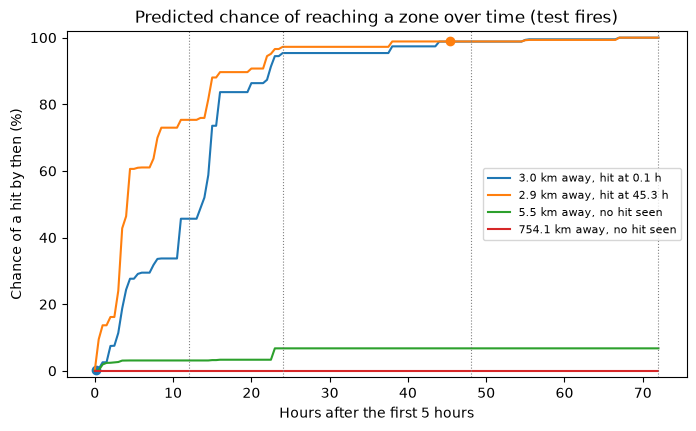

In [3]:
# Pick 4 test fires: two that hit (early and late) and two that never hit (near and far)
hits = test[test[EVENT_COL] == 1].sort_values(TIME_COL)
miss = test[test[EVENT_COL] == 0].sort_values("dist_min_ci_0_5h")
examples = pd.concat([hits.head(1), hits.tail(1), miss.head(1), miss.tail(1)])
hours = np.linspace(0, 72, 145)
curves = model.predict_curve(examples[FEATURES], hours)

# Plot each fire's curve; a dot marks the actual hit time
plt.figure(figsize=(8, 4.5))
for (_, r), c in zip(examples.iterrows(), curves):
    what = f"hit at {r[TIME_COL]:.1f} h" if r[EVENT_COL] == 1 else "no hit seen"
    line, = plt.plot(hours, c * 100, label=f"{r['dist_min_ci_0_5h'] / 1000:.1f} km away, {what}")
    if r[EVENT_COL] == 1: plt.plot(r[TIME_COL], np.interp(r[TIME_COL], hours, c * 100), "o", color=line.get_color())
for h in (12, 24, 48, 72): plt.axvline(h, color="grey", linestyle=":", linewidth=0.8)
plt.title("Predicted chance of reaching a zone over time (test fires)")
plt.xlabel("Hours after the first 5 hours"); plt.ylabel("Chance of a hit by then (%)"); plt.ylim(-2, 102)
plt.legend(fontsize=8); plt.savefig(FIG_DIR / "03_survival_curves.png", bbox_inches="tight"); plt.show()

## 3. Predicted vs. actual time to hit
The predicted time is when a fire's chance of a hit passes 50%. Points near the dashed line = good timing.

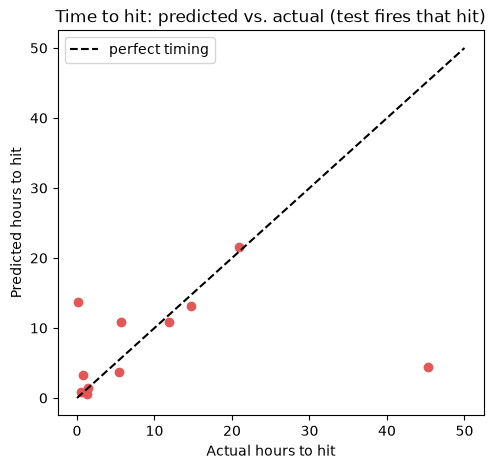

Median timing error for fires that hit: 1.6 hours
Fires that never hit and got no predicted time: 23 of 23


In [4]:
# Predicted time to hit for each test fire
pred_time = model.predict_time(X)
hit = test[EVENT_COL].to_numpy() == 1

# Scatter for the fires that really hit; and how many non-hits were correctly given no time
plt.figure(figsize=(5.5, 5))
plt.scatter(test.loc[hit, TIME_COL], pred_time[hit], color="#E45756")
plt.plot([0, 50], [0, 50], "k--", label="perfect timing")
plt.title("Time to hit: predicted vs. actual (test fires that hit)")
plt.xlabel("Actual hours to hit"); plt.ylabel("Predicted hours to hit"); plt.legend()
plt.savefig(FIG_DIR / "03_time_to_hit.png", bbox_inches="tight"); plt.show()
err = np.abs(pred_time[hit] - test.loc[hit, TIME_COL].to_numpy())
print("Median timing error for fires that hit: %.1f hours" % np.nanmedian(err))
print("Fires that never hit and got no predicted time: %d of %d" % (np.isnan(pred_time[~hit]).sum(), (~hit).sum()))

## 4. Can we trust the percentages?
If the model says 30%, about 30% of those fires should really hit. Points close to the dashed line = good.

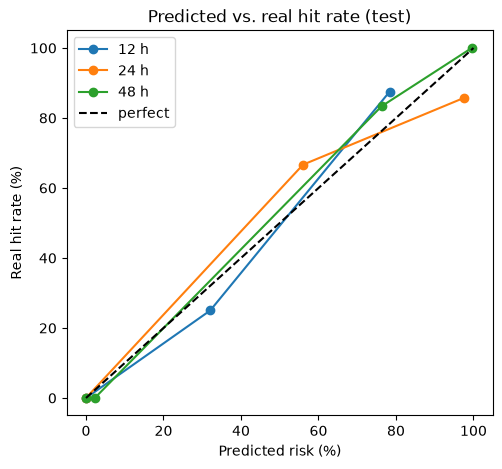

In [5]:
# Calibration: predicted risk vs. how often fires really hit, per time limit
plt.figure(figsize=(5.5, 5))
for k, h in enumerate([12, 24, 48]):
    known = labels[f"hit_{h}h"].notna()
    real, pred = calibration_curve(labels.loc[known, f"hit_{h}h"], probs[known, k], n_bins=4, strategy="quantile")
    plt.plot(pred * 100, real * 100, "o-", label=f"{h} h")
# Dashed line = perfect calibration
plt.plot([0, 100], [0, 100], "k--", label="perfect")
plt.title("Predicted vs. real hit rate (test)")
plt.xlabel("Predicted risk (%)"); plt.ylabel("Real hit rate (%)"); plt.legend()
plt.savefig(FIG_DIR / "03_calibration.png", bbox_inches="tight"); plt.show()

## 5. Which features matter most?
Shuffle one feature at a time: the bigger the score drop, the more important the feature.

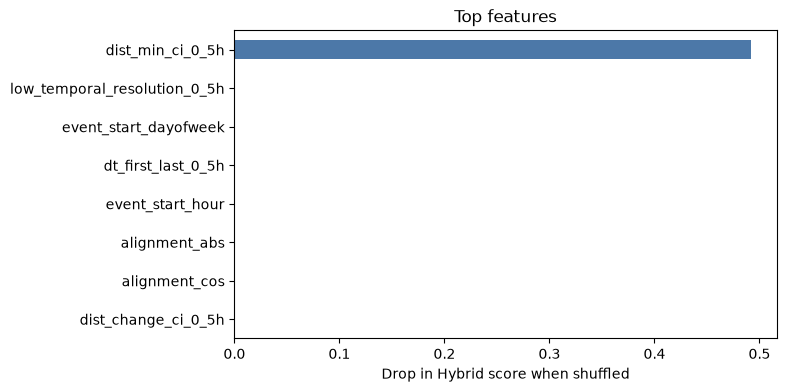

In [6]:
# Shuffle each feature and measure the drop in Hybrid score
imp = permutation_importance(model, X, y, scoring=hybrid_scorer, n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(8)
# Bar chart of the most important features, saved as a PNG
imp.plot.barh(color="#4C78A8", figsize=(7, 4))
plt.title("Top features"); plt.xlabel("Drop in Hybrid score when shuffled")
plt.savefig(FIG_DIR / "03_feature_importance.png", bbox_inches="tight"); plt.show()

## 6. Risk bands (48 h)
Low 0–25% · Medium 25–50% · High 50–75% · Critical 75–100%

In [7]:
# Group test fires into risk bands and count real hits in each band
known = labels["hit_48h"].notna()
bands = pd.DataFrame({"band": risk_band(probs[known, 2] * 100), "hit": labels.loc[known, "hit_48h"].to_numpy()})
bands.groupby("band", observed=False)["hit"].agg(fires="count", real_hits="sum").astype(int)

,fires,real_hits
band,,
Low,13,0
Medium,0,0
High,0,0
Critical,11,11


## 7. Try it on new fires
Take 8 fires from the competition file (no answers) and run `src/predict.py`.

In [8]:
# Pick 8 competition fires from near to far and save them as a sample input
new = pd.read_csv(DATA_DIR / "raw" / "test.csv")
new.sort_values("dist_min_ci_0_5h").iloc[::12].head(8).to_csv(DATA_DIR / "test" / "sample_input.csv", index=False)

# Run the prediction script on the sample, then show the results
subprocess.run([sys.executable, "src/predict.py", "--input", "data/test/sample_input.csv",
                "--output", "data/test/sample_predictions.csv"], cwd=ROOT, check=True)
pd.read_csv(DATA_DIR / "test" / "sample_predictions.csv")[["event_id", "predicted_hours_to_hit", "risk_12h_pct", "risk_24h_pct", "risk_48h_pct", "risk_band"]]

Saved 8 predictions to data/test/sample_predictions.csv
 event_id  predicted_hours_to_hit  risk_percentage risk_band
 27052376                     0.5            99.95  Critical
 37196135                    13.7            96.42  Critical
 54801108                     1.9            99.67  Critical
 42997746                     NaN             1.37       Low
 96570675                     NaN             0.00       Low
 99649465                     NaN             0.00       Low
 39717591                     NaN             0.22       Low
 49169401                     NaN             0.00       Low


,event_id,predicted_hours_to_hit,risk_12h_pct,risk_24h_pct,risk_48h_pct,risk_band
0,27052376,0.5,97.95,99.78,99.95,Critical
1,37196135,13.7,46.11,90.73,96.42,Critical
2,54801108,1.9,95.86,98.43,99.67,Critical
3,42997746,NaN,1.37,1.37,1.37,Low
4,96570675,NaN,0.00,0.00,0.00,Low
5,99649465,NaN,0.00,0.00,0.00,Low
6,39717591,NaN,0.00,0.22,0.22,Low
7,49169401,NaN,0.00,0.00,0.00,Low


Create the competition submission for all 95 fires:

In [9]:
# Predict all competition fires and write the submission file
subprocess.run([sys.executable, "src/predict.py", "--input", "data/raw/test.csv", "--output", "reports/test_predictions.csv",
                "--submission", "reports/submission.csv"], cwd=ROOT, check=True, capture_output=True)
pd.read_csv(ROOT / "reports" / "submission.csv").head()

,event_id,prob_12h,prob_24h,prob_48h,prob_72h
0,10662602,0.0000,0.0000,0.0000,0.0000
1,13353600,0.5814,0.9816,0.9980,1.0000
2,13942327,0.0000,0.0000,0.0000,0.0000
3,16112781,0.7592,0.9610,0.9854,1.0000
4,17132808,0.0442,0.0442,0.0442,0.0442


## Summary
**Good**
- A survival model at the core: it predicts *when* a fire will hit and handles censored fires correctly.
- High Hybrid score on unseen fires, and the percentages are reliable.
- Fires that never hit get no predicted hit time.

**Not so good**
- Most hit times are close (see the median timing error above), but a few late hits are predicted far too early.
- Depends almost only on distance.

**Limits:** only 221 fires in total; no weather, wind or terrain data. Beyond the last observed time (about 67 h) the curve is held flat, so the 72 h risk equals the risk at the end of the data.